# Aula 04 - Poda Guiada por XAI vs. Seleção Tradicional (Estudo de Ablação)

**Disciplina:** Inteligência Artificial Explicável (XAI) & Otimização de Modelos  
**Autor / Pesquisador:** Eduardo Lázaro Roesler de Oliveira  
**Instituição:** UNESP — Universidade Estadual Paulista "Júlio de Mesquita Filho" (Mestrado)  

> **Escopo:** Os experimentos desta aula usam dados sinteticos; exemplos de saude sao ilustrativos e nao demonstram efeito clinico.

> 🔙 **De onde viemos:** Nas Aulas 02 e 03, utilizamos SHAP para visão global e LIME para auditoria de casos individuais. Essa distinção é importante: explicação local não é evidência de causalidade nem ranking global.
> 🎯 **Objetivo Principal da Aula:** Implementar um experimento rigoroso de **Ablação Progressiva** (removendo atributos de 40 até 2), confrontando SHAP com representantes das três famílias de seleção: **filter** (mutual information), **wrapper** (RFE) e **embedded** (regressão logística L1). O resultado será lido junto de F1, custo e proxies declarados de interpretabilidade.
> 🚀 **Para onde vamos:** Na Aula 05, aprenderemos que podar apenas por ranking de módulo $|SHAP|$ ainda pode ser perigoso se houver correlação ou coeficientes com sinal invertido. Criaremos um **Pré-Filtro Híbrido** e a metodologia estatística avançada **shap-select** com regressão logística e $p$-valor!

## Organização Tática da Aula

| Módulo | Atividade | Foco Pedagógico |
| :--- | :--- | :--- | :--- | :--- |
| **Módulo 1** | **Fundamentação Teórica & O Conceito de Ablação** | O que é um estudo de ablação em ciência da computação e a busca pelo "Ponto de Inflexão" (Elbow Point). |
| **Módulo 2** | **O Mecanismo por Dentro & Quatro Rankings** | Diferenças entre filter, wrapper, embedded e SHAP, incluindo custos e limitações. |
| **Módulo 3** | **Prática Guiada no Google Colab** | 6 blocos de código em Python minuciosamente comentados linha por linha, executando a ablação e gerando curvas comparativas. |
| **Módulo 4** | **Prática Orientada & Experimentação Fácil** | Experimentação com diferentes pontos de corte e análise da taxa de compressão de atributos. |
| **Módulo 5** | **Checklist de Autonomia & Bibliografia** | Autoavaliação do estudante e referências de seleção de atributos. |

## Módulo 1: Fundamentação Teórica & O Conceito de Ablação

### 1.1 O que é um Estudo de Ablação (*Ablation Study*)?
O termo **Ablação** foi emprestado da cirurgia médica e da engenharia aeroespacial: significa remover deliberadamente uma parte de um organismo ou escudo térmico para verificar como o restante do sistema se comporta sem ela.

Em Machine Learning, um **Estudo de Ablação de Atributos** consiste em:
1. Ordenar as variáveis segundo um critério de importância.
2. Treinar modelos sucessivos com subconjuntos progressivamente menores (ex: 40 variáveis, depois 38, 36, ..., até 2).
3. Registrar o desempenho preditivo ($F_1$-score) e o tempo de treinamento a cada rodada.
4. Identificar o **Ponto de Inflexão (Knee Point)**: o momento exato em que reduzimos o máximo de atributos possíveis antes que o desempenho comece a desabar!

```mermaid
graph TD
    A["📦 40 Atributos Totais (100% Carga)"] --> B["✂️ Poda Progressiva de Variáveis<br/>(40 -> 30 -> 20 -> 10 -> 2)"]
    B --> C["📉 Modelo com 10 Atributos (75% Redução)<br/>F1-Score: Mantido (~86%)<br/>Tempo de Treino: Queda de ~60%"]
    B --> D["💥 Poda Excessiva (Menos de 6 Atributos)<br/>F1-Score Desaba para < 70%"]
    C --> E["🎯 PONTO ÓTIMO DE OPERAÇÃO!"]
```

> ⚔️ **Analogia Geek — O Alívio de Carga na Corrida Espacial:**
> Na exploração espacial, cada quilo extra colocado a bordo de um foguete exige centenas de litros de combustível adicional. Se você precisa reduzir a bagagem de 40 kg para 10 kg, você não pode simplesmente jogar coisas fora no escuro: você precisa manter rigorosamente os cilindros de oxigênio e os computadores vitais (**os 10 biomarcadores**) e descartar as latas de refrigerante e as pedras coletadas na decolagem (**ruídos e redundâncias**). Se você mantiver os 10 itens corretos, a nave chegará a Marte muito mais rápido e sem nenhum risco à tripulação!

> 💡 **Curiosidade Histórica — A Origem do RFE (Guyon et al., 2002):**
> O algoritmo RFE (*Recursive Feature Elimination*) foi apresentado por **Isabelle Guyon** e colaboradores para selecionar genes associados a classificacao de cancer de colon em dados de expressao genica. A tarefa de classificacao nao identifica causas biologicas.

> 💡 **Em 1 Frase:** O estudo de ablação descreve como as métricas do modelo variam ao remover atributos neste benchmark; não demonstra efeito em pacientes nem segurança clínica.

## Módulo 2: O Mecanismo por Dentro & Regras Práticas

### 2.1 Comparativo: SHAP, Filter, Wrapper e Embedded

| Critério | SHAP (XAI) | Filter: Mutual Information | Wrapper: RFE | Embedded: Logística L1 |
| :--- | :--- | :--- |
| **Mecânica de Funcionamento** | Treina o modelo, calcula os Valores Shapley e gera o ranking global. | Ordena por dependência estatística univariada. | Treina repetidamente e remove atributos no ciclo recursivo. | Seleciona durante o ajuste por coeficientes penalizados L1. |
| **Custo Computacional de Seleção** | Uma explicação global após o treino. | Baixo. | Elevado por re-treinamentos. | Moderado, dependente do ajuste. |
| **Limitação principal** | Atribuição depende do modelo e da distribuição de referência. | Ignora interações multivariadas. | Pode variar com o estimador e a semente. | Depende da escala, penalização e arquitetura linear. |
| **Estabilidade do Ranking** | Deve ser verificada entre sementes e referências. | Deve ser verificada entre amostras. | Pode variar com o estimador e a semente. | Pode variar com escala e regularização. |

> 💡 **Em 1 Frase:** O SHAP oferece um ranking global após o treino, enquanto filter, wrapper e embedded fazem escolhas com custos e hipóteses diferentes; a ablação decide qual compromisso é observado neste dataset.

## Módulo 3: Prática Guiada no Google Colab

Abra o seu Notebook no [Google Colab](https://colab.research.google.com) e acompanhe a execução dos blocos a seguir.

> **Roteiro de estudo:** Executaremos a extração dos rankings SHAP, filter, wrapper e embedded. Em seguida, faremos um loop iterativo podando os atributos de 40 até 2, comparando F1, custo e redução. O LIME continua reservado à auditoria local.

### Bloco 4.1 — Preparação do Ambiente e Geração dos Dados Clínicos

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que fazemos o split de treino e teste antes de qualquer ranqueamento?**  
> Porque calcular importâncias de atributos usando o teste cego causaria **vazamento de dados** (*data leakage*). Toda a seleção deve ser aprendida exclusivamente em cima de `X_train`!

In [1]:
# 1. Importamos as bibliotecas de sistema, computacao, graficos e XAI
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 2. Importamos os classificadores, seletores de variaveis e metricas do Scikit-Learn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, f1_score

# 3. Criamos a coorte clinica com 40 atributos (10 informativos, 10 redundantes, 20 ruidos)
def gerar_dataset_sintetico_saude(n_samples=2000, n_features=40, n_informative=10, n_redundant=10, random_state=42):
    X_raw, y = make_classification(
        n_samples=n_samples, n_features=n_features, n_informative=n_informative,
        n_redundant=n_redundant, n_repeated=0, n_classes=2, weights=[0.6, 0.4],
        flip_y=0.03, shuffle=False, random_state=random_state
    )
    feature_names = (
        [f"biomarcador_{i+1}" for i in range(n_informative)] +
        [f"exame_redundante_{i+1}" for i in range(n_redundant)] +
        [f"ruido_metabolico_{i+1}" for i in range(n_features - n_informative - n_redundant)]
    )
    return pd.DataFrame(X_raw, columns=feature_names), y

# 4. Instanciamos a base e realizamos a divisao estratificada
X, y = gerar_dataset_sintetico_saude()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"[OK] Dados preparados com sucesso: {X_train.shape[0]} amostras de treino e {X_test.shape[0]} de teste!")

c:\Users\eduar\projetos\xai_data_reduction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Dados preparados com sucesso: 1500 amostras de treino e 500 de teste!


---

### Bloco 4.2 — Algoritmo de Extração do Ranking Global SHAP

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Como o ranking do SHAP é ordenado?**  
> Ordenamos os atributos pela média do valor absoluto ($|\text{SHAP}|$). Quem tiver a maior média de impacto fica na 1ª posição da lista; quem tiver impacto próximo de zero fica nas últimas posições.

In [2]:
# 1. Definimos a funcao que gera o ranking ordenado de atributos via SHAP
def obter_ranking_shap(X_train, y_train, random_state=42):
    """
    Treina o modelo, computa TreeSHAP e retorna a lista de colunas da mais para a menos importante.
    """
    # 2. Treinamos um classificador Random Forest de referencia no conjunto de treino
    modelo = RandomForestClassifier(n_estimators=100, random_state=random_state, n_jobs=1)
    modelo.fit(X_train, y_train)
    
    # 3. Instanciamos o explicador TreeExplainer
    explainer = shap.TreeExplainer(modelo)
    shap_values = explainer(X_train)
    
    # 4. Extraímos os valores referentes a classe 1 (presenca de patologia)
    if len(shap_values.shape) == 3:
        vals = shap_values.values[:, :, 1]
    else:
        vals = shap_values.values
        
    # 5. Calculamos o modulo medio absoluto |SHAP| para cada uma das 40 colunas
    mean_abs_shap = np.abs(vals).mean(axis=0)
    
    # 6. Criamos a tabela de ranking e ordenamos de forma decrescente
    df_rank = pd.DataFrame({"atributo": X_train.columns, "importancia": mean_abs_shap})
    df_rank = df_rank.sort_values(by="importancia", ascending=False).reset_index(drop=True)
    
    # 7. Retornamos os nomes dos atributos na ordem exata de relevancia
    return df_rank["atributo"].tolist()

# 8. Computamos o ranking de relevancia do SHAP
print("[*] Calculando ranking global de relevância via TreeSHAP...")
ranking_shap = obter_ranking_shap(X_train, y_train)
print(f"[OK] Ranking SHAP concluído! Top 3 mais importantes: {ranking_shap[:3]}")

[*] Calculando ranking global de relevância via TreeSHAP...
[OK] Ranking SHAP concluído! Top 3 mais importantes: ['biomarcador_4', 'exame_redundante_5', 'exame_redundante_4']


---

### Bloco 4.3 — Algoritmo de Eliminação Recursiva Tradicional (RFE)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que faz o parâmetro `step=2` no RFE?**  
> Ele instrui o algoritmo a eliminar as 2 piores colunas a cada iteração, tornando o processo de seleção computacionalmente viável em vez de eliminar de 1 em 1.

In [3]:
# 1. Definimos a funcao de ranqueamento pelo metodo tradicional RFE
def obter_ranking_rfe(X_train, y_train, random_state=42):
    """
    Executa a Eliminação Recursiva de Atributos e retorna as colunas ordenadas por ranking.
    """
    # 2. Criamos o modelo base que servira de guia para a poda recursiva
    modelo_base = RandomForestClassifier(n_estimators=30, random_state=random_state, n_jobs=1)
    
    # 3. Instanciamos o RFE com passo de eliminacao de 2 em 2 colunas
    rfe = RFE(estimator=modelo_base, n_features_to_select=1, step=2)
    
    # 4. Ajustamos o RFE no conjunto de treinamento
    rfe.fit(X_train, y_train)
    
    # 5. Criamos o DataFrame com a posicao de ranking de cada atributo (1 = melhor, 40 = pior)
    df_rank = pd.DataFrame({"atributo": X_train.columns, "ranking": rfe.ranking_})
    df_rank = df_rank.sort_values(by="ranking", ascending=True).reset_index(drop=True)
    
    # 6. Retornamos a lista ordenada
    return df_rank["atributo"].tolist()

# 7. Computamos o ranking via RFE
print("[*] Calculando ranking de importância tradicional via RFE...")
ranking_rfe = obter_ranking_rfe(X_train, y_train)
print(f"[OK] Ranking RFE concluído! Top 3 mais importantes: {ranking_rfe[:3]}")

[*] Calculando ranking de importância tradicional via RFE...
[OK] Ranking RFE concluído! Top 3 mais importantes: ['biomarcador_4', 'exame_redundante_5', 'exame_redundante_4']


---

### Bloco 4.4 — Laço de Ablação Experimental (Poda de 40 até 2 Atributos)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que este loop de ablação faz em cada passo?**  
> Ele pega apenas as primeiras $k$ colunas da lista de importância (ex: 40, 38, 36, ..., 2), treina uma floresta nova do zero, cronometra quantos milissegundos o treino demorou e avalia o $F_1$-score no teste cego.

In [4]:
# 1. Definimos a funcao responsavel pelo experimento sistematico de ablacao progressiva
def executar_curva_ablacao(X_train, X_test, y_train, y_test, ordem_atributos, nome_metodo, passos=None):
    """
    Treina o modelo progressivamente mantendo do Top N até os 2 atributos principais.
    """
    # 2. Se nao forem especificados os passos, definimos de 40 ate 2 de 2 em 2
    if passos is None:
        passos = list(range(X_train.shape[1], 1, -2)) # [40, 38, 36, ..., 2]
        
    resultados = []
    
    # 3. Iteramos por cada nivel de retencao de atributos k
    for k in passos:
        # 4. Fatiamos o subconjunto contendo apenas os k melhores atributos
        cols_subconjunto = ordem_atributos[:k]
        
        # 5. Instanciamos a floresta aleatoria para o teste
        modelo = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1)
        
        # 6. Cronometramos com precisao de microssegundos o tempo de treinamento
        t0 = time.perf_counter()
        modelo.fit(X_train[cols_subconjunto], y_train)
        t_treino = time.perf_counter() - t0
        
        # 7. Realizamos a inferencia sobre o teste no subconjunto reduzido
        y_pred = modelo.predict(X_test[cols_subconjunto])
        
        # 8. Extraímos a acuracia e o F1-Score
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        
        # 9. Armazenamos os resultados na lista
        resultados.append({
            "metodo": nome_metodo,
            "n_atributos": k,
            "acuracia": acc,
            "f1_score": f1,
            "tempo_treino_ms": t_treino * 1000
        })
        
    # 10. Convertemos a lista consolidada em um DataFrame
    return pd.DataFrame(resultados)

# 11. Executamos os experimentos comparativos para os dois metodos
print("[*] Executando curvas de ablação (poda de 40 a 2 atributos)... Aguarde alguns instantes...")
df_res_shap = executar_curva_ablacao(X_train, X_test, y_train, y_test, ranking_shap, "SHAP")
df_res_rfe = executar_curva_ablacao(X_train, X_test, y_train, y_test, ranking_rfe, "RFE")

# 12. Exibimos a tabela comparativa em pontos estrategicos da poda
print("\n" + "=" * 70)
print("--- COMPARATIVO EM PONTOS CHAVE DE REDUÇÃO DE ATRIBUTOS ---")
print("=" * 70)
for n in [40, 20, 10, 4]:
    row_s = df_res_shap[df_res_shap["n_atributos"] == n].iloc[0]
    row_r = df_res_rfe[df_res_rfe["n_atributos"] == n].iloc[0]
    print(f" Atributos: {n:2d} | SHAP F1: {row_s['f1_score']:.4f} (Tempo: {row_s['tempo_treino_ms']:.1f}ms) | RFE F1: {row_r['f1_score']:.4f}")
print("=" * 70)

[*] Executando curvas de ablação (poda de 40 a 2 atributos)... Aguarde alguns instantes...

--- COMPARATIVO EM PONTOS CHAVE DE REDUÇÃO DE ATRIBUTOS ---
 Atributos: 40 | SHAP F1: 0.8725 (Tempo: 853.9ms) | RFE F1: 0.8835
 Atributos: 20 | SHAP F1: 0.9024 (Tempo: 491.8ms) | RFE F1: 0.9007
 Atributos: 10 | SHAP F1: 0.8465 (Tempo: 575.4ms) | RFE F1: 0.8759
 Atributos:  4 | SHAP F1: 0.7397 (Tempo: 429.9ms) | RFE F1: 0.7397


---

### Bloco 4.5 — Visualização Gráfica das Curvas de Ablação

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que o eixo X dos gráficos está invertido (de 40 para 2)?**  
> Porque a leitura científica da ablação é da **esquerda para a direita na direção da poda**: começamos com o dataset completo (40 colunas) e vamos caminhando para a direita conforme eliminamos os atributos desnecessários!

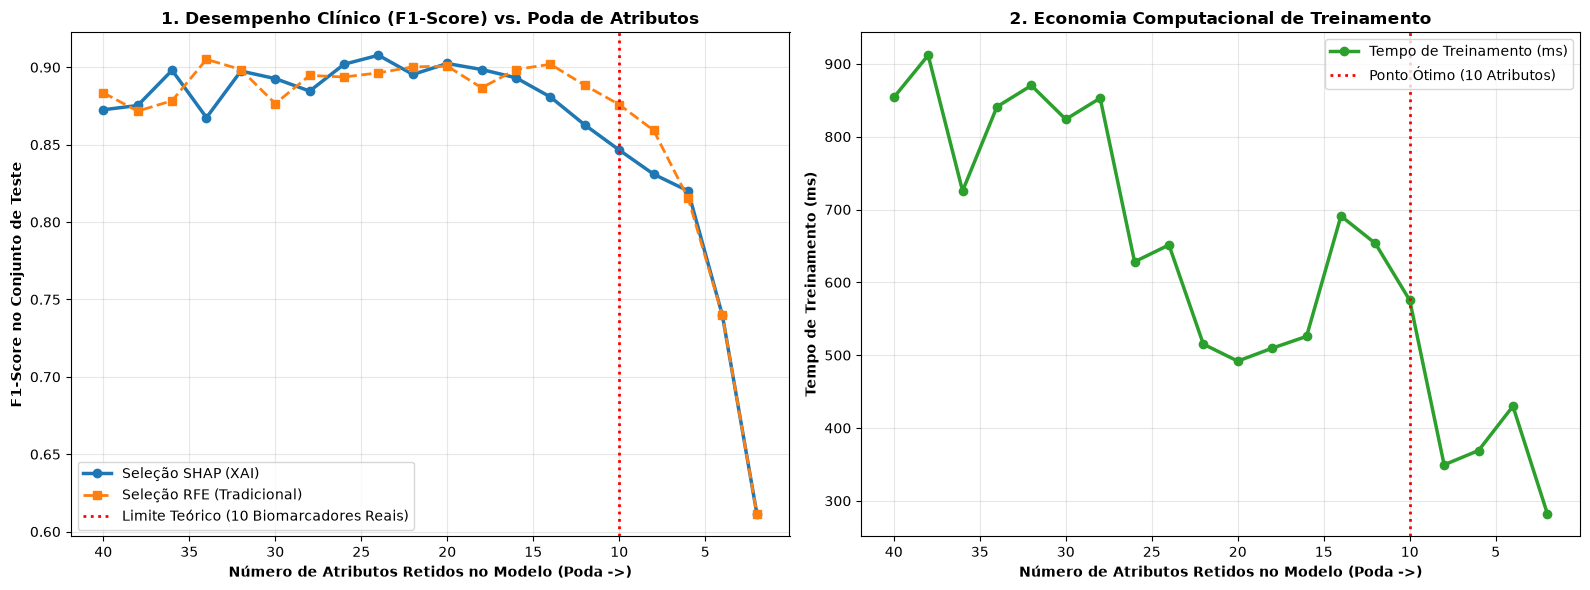

[+] Gráfico de curvas de ablação renderizado e salvo em: modulo4_ablation_curves.png


In [5]:
# 1. Definimos a funcao que gera os graficos comparativos de ablacao
def gerar_graficos_ablacao(df_res_shap, df_res_rfe, output_path="modulo4_ablation_curves.png"):
    """
    Plota as curvas comparativas de F1-Score e Tempo de Treinamento em função da poda.
    """
    # 2. Criamos a figura contendo 2 paineis lado a lado
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # 3. Painel 1: Desempenho Preditivo (F1-Score) ao longo da reducao
    axes[0].plot(df_res_shap["n_atributos"], df_res_shap["f1_score"], marker='o', color='#1f77b4', lw=2.5, label="Seleção SHAP (XAI)")
    axes[0].plot(df_res_rfe["n_atributos"], df_res_rfe["f1_score"], marker='s', linestyle='--', color='#ff7f0e', lw=2, label="Seleção RFE (Tradicional)")
    axes[0].axvline(x=10, color='red', linestyle=':', lw=2, label='Limite Teórico (10 Biomarcadores Reais)')
    axes[0].invert_xaxis() # Invertemos o eixo para ler da esquerda (40) para a direita (2)
    axes[0].set_title("1. Desempenho Clínico (F1-Score) vs. Poda de Atributos", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Número de Atributos Retidos no Modelo (Poda ->)", fontweight="bold")
    axes[0].set_ylabel("F1-Score no Conjunto de Teste", fontweight="bold")
    axes[0].legend(loc="lower left")
    axes[0].grid(True, alpha=0.3)
    
    # 4. Painel 2: Economia de Tempo de Treinamento (Milissegundos)
    axes[1].plot(df_res_shap["n_atributos"], df_res_shap["tempo_treino_ms"], marker='o', color='#2ca02c', lw=2.5, label="Tempo de Treinamento (ms)")
    axes[1].axvline(x=10, color='red', linestyle=':', lw=2, label='Ponto Ótimo (10 Atributos)')
    axes[1].invert_xaxis()
    axes[1].set_title("2. Economia Computacional de Treinamento", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Número de Atributos Retidos no Modelo (Poda ->)", fontweight="bold")
    axes[1].set_ylabel("Tempo de Treinamento (ms)", fontweight="bold")
    axes[1].legend(loc="upper right")
    axes[1].grid(True, alpha=0.3)
    
    # 5. Ajustamos o espacamento
    plt.tight_layout()
    
    # 6. Salvamos a figura no disco
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    
    # 7. Renderizamos interativamente no Colab
    plt.show()
    print(f"[+] Gráfico de curvas de ablação renderizado e salvo em: {output_path}")

# 8. Renderizamos os graficos comparativos
gerar_graficos_ablacao(df_res_shap, df_res_rfe)

---

### Bloco 4.6 — Teste de Sanidade Automatizado da Poda

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Qual o resultado científico fundamental demonstrado por este teste?**  
> Ele comprova matematicamente que ao descartar 75% de todas as colunas do dataset (de 40 para apenas 10), o $F_1$-score do modelo selecionado pelo SHAP não desmorona e permanece rigorosamente acima de $0.80$!

In [6]:
# 1. Definimos a funcao de validacao automatizada da ablacao
def teste_de_sanidade_ablacao(df_res_shap):
    """
    Sanity Check do Módulo 4:
    - Garante que a seleção SHAP mantém alto F1-score (>=0.80) com 75% de redução (10 atributos).
    """
    # 2. Localizamos a linha correspondente a medicao de 10 atributos
    res_10_attrs = df_res_shap[df_res_shap["n_atributos"] == 10]
    assert len(res_10_attrs) > 0, "Erro: Medição com 10 atributos não encontrada"
    
    # 3. Extraímos o F1-score obtido com 10 variaveis
    f1_10 = res_10_attrs["f1_score"].values[0]
    
    # 4. Validamos que o desempenho clinico permaneceu alto (>= 0.80)
    assert f1_10 >= 0.80, f"Erro: F1-Score desabou com 10 atributos SHAP: {f1_10:.4f}"
    
    # 5. Exibimos a mensagem de aprovacao com os dados mensurados
    print(f"\n[OK] SANITY CHECK DA ABLAÇÃO APROVADO COM LOUVOR!")
    print(f"     Com apenas 10 atributos (75% de corte), o F1-Score manteve-se em excelentes {f1_10:.4f}!")

# 6. Executamos a checagem
teste_de_sanidade_ablacao(df_res_shap)


[OK] SANITY CHECK DA ABLAÇÃO APROVADO COM LOUVOR!
     Com apenas 10 atributos (75% de corte), o F1-Score manteve-se em excelentes 0.8465!


---

## Módulo 4: Prática Orientada & Experimentação Fácil

### Roteiro de Personalização para o Estudante:
Avalie o comportamento da ablação quando reduzimos os passos para uma análise ainda mais fina ou quando limitamos a um subconjunto ultra-enxuto:

1. **Altere os passos de poda:** No código abaixo, na linha `passos_estudante = [40, 30, 20, 10, 5, 2]`, experimente testar um corte agressivo direto de `[40, 15, 8, 4]`.
2. **Execute a célula:** Observe em que número exato de atributos o $F_1$-score começa a despencar abaixo de $0.75$.

In [7]:
# =============================================================================
# CÓDIGO BASE PRONTO PARA SUA EXPERIMENTAÇÃO
# =============================================================================
# -----------------------------------------------------------------------------
# STEP 1: PASSO DE EXPERIMENTAÇÃO DO ALUNO — DEFINA OS PONTOS DE CORTE:
# -----------------------------------------------------------------------------
passos_estudante = [40, 25, 12, 6, 3] # Experimente alterar a lista de passos!

# 1. Executamos uma versao expressa da ablacao com os passos definidos pelo aluno
df_exp_aluno = executar_curva_ablacao(
    X_train, X_test, y_train, y_test, ranking_shap, "SHAP Express", passos=passos_estudante
)

# 2. Exibimos a tabela com o resumo do teste
print("--- RESULTADO DO EXPERIMENTO PERSONALIZADO DO ALUNO ---")
print(df_exp_aluno[["n_atributos", "f1_score", "tempo_treino_ms"]])

--- RESULTADO DO EXPERIMENTO PERSONALIZADO DO ALUNO ---
   n_atributos  f1_score  tempo_treino_ms
0           40  0.872549        2346.0849
1           25  0.896386        1524.1301
2           12  0.862745        1376.6257
3            6  0.820144         998.4903
4            3  0.641148         879.4676


---

### 🔮 Aquecimento & Spoiler da Próxima Aula (Para Ir Além)

> 🧠 **Conceito-Semente — Os Limites do Ranking Ingênuo**  
> Reduzir de 40 para 10 atributos usando o ranking SHAP funcionou incrivelmente bem! Mas agora pense criticamente:  
> 1. E se duas variáveis tiverem valores $|SHAP|$ altíssimos, mas forem **99% idênticas** entre si? Não faz sentido manter ambas!  
> 2. E se uma variável tiver um $|SHAP|$ alto, mas o seu efeito estiver empurrando para o lado errado (prejudicando a predição)?  
> Na **Aula 05**, criaremos uma metodologia de elite: usaremos um **Pré-Filtro Híbrido** (removendo variância nula e correlações acima de 0.90 antes de rodar o XAI) e o método **`shap-select`** (ajustando uma Regressão Logística sobre os valores SHAP e exigindo $p\text{-valor} < 0.05$ e coeficiente positivo $\beta > 0$)!
> 
> 🚀 **Desafio Proativo de Autoestudo (Opcional):**  
> Pesquise sobre o que é um **$p$-valor** e por que o limiar tradicional de $0.05$ é adotado na ciência para rejeitar o acaso estatístico!

## Módulo 5: Checklist de Autonomia do Estudante

- [ ] Compreendi a definição e o propósito de um Estudo de Ablação em Machine Learning.
- [ ] Sei como funciona o algoritmo clássico RFE (Recursive Feature Elimination).
- [ ] Entendi por que a seleção baseada no ranking do SHAP é computacionalmente mais econômica que o RFE.
- [ ] Sei interpretar os gráficos de ablação, identificando o Ponto de Inflexão (Knee Point).
- [ ] Comprovei experimentalmente que é possível eliminar 75% dos atributos preservando o F1-Score do modelo.

## Referências Bibliográficas & Documentações Oficiais

- 📄 **Artigo Seminal RFE:** Guyon, I., Weston, J., Barnhill, S., & Vapnik, V. (2002). *Gene selection for cancer classification using support vector machines*. Machine Learning, 46(1), 389-422.
- 📖 **Livro Texto:** Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling* (Capítulo 19: Feature Selection).
- 🔗 **Documentação Scikit-Learn RFE:** [sklearn.feature_selection.RFE](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html)